## Task 1 — Data exploration and cohort feasibility

#### Step 1: Load tables and explore

In [3]:
import sys, pandas as pd
print(sys.executable)
print(pd.__version__)

/Users/mehalgosalia/anaconda3/envs/gibleed/bin/python
3.1.0


In [4]:
import os
directory = 'GiBleed_5.5'
print(sorted(os.listdir(directory)))

['CARE_SITE.csv', 'CDM_SOURCE.csv', 'COHORT.csv', 'COHORT_DEFINITION.csv', 'CONCEPT.csv', 'CONCEPT_ANCESTOR.csv', 'CONCEPT_CLASS.csv', 'CONCEPT_METADATA.csv', 'CONCEPT_RELATIONSHIP.csv', 'CONCEPT_RELATIONSHIP_METADATA.csv', 'CONCEPT_SYNONYM.csv', 'CONDITION_ERA.csv', 'CONDITION_OCCURRENCE.csv', 'COST.csv', 'DEATH.csv', 'DEVICE_EXPOSURE.csv', 'DOMAIN.csv', 'DOSE_ERA.csv', 'DRUG_ERA.csv', 'DRUG_EXPOSURE.csv', 'DRUG_STRENGTH.csv', 'EPISODE.csv', 'EPISODE_EVENT.csv', 'FACT_RELATIONSHIP.csv', 'LOCATION.csv', 'MEASUREMENT.csv', 'METADATA.csv', 'NOTE.csv', 'NOTE_NLP.csv', 'OBSERVATION.csv', 'OBSERVATION_PERIOD.csv', 'PACK_CONTENT.csv', 'PAYER_PLAN_PERIOD.csv', 'PERSON.csv', 'PROCEDURE_OCCURRENCE.csv', 'PROVIDER.csv', 'RELATIONSHIP.csv', 'SOURCE_TO_CONCEPT_MAP.csv', 'SPECIMEN.csv', 'VISIT_DETAIL.csv', 'VISIT_OCCURRENCE.csv', 'VOCABULARY.csv']


In [5]:
table_names = ['PERSON', 'OBSERVATION_PERIOD', 'DRUG_EXPOSURE',
               'CONDITION_OCCURRENCE', 'VISIT_OCCURRENCE', 'CONCEPT', 'CONCEPT_ANCESTOR']
tables = {}

for name in table_names:
    path = os.path.join(directory, name + ".csv")   # build the file name from `name`
    tables[name] = pd.read_csv(path)       # read the file at `path`
    print(name, len(tables[name]), list(tables[name].columns))              # number of rows, list of columns

PERSON 2694 ['PERSON_ID', 'GENDER_CONCEPT_ID', 'YEAR_OF_BIRTH', 'MONTH_OF_BIRTH', 'DAY_OF_BIRTH', 'BIRTH_DATETIME', 'RACE_CONCEPT_ID', 'ETHNICITY_CONCEPT_ID', 'LOCATION_ID', 'PROVIDER_ID', 'CARE_SITE_ID', 'PERSON_SOURCE_VALUE', 'GENDER_SOURCE_VALUE', 'GENDER_SOURCE_CONCEPT_ID', 'RACE_SOURCE_VALUE', 'RACE_SOURCE_CONCEPT_ID', 'ETHNICITY_SOURCE_VALUE', 'ETHNICITY_SOURCE_CONCEPT_ID']
OBSERVATION_PERIOD 5343 ['OBSERVATION_PERIOD_ID', 'PERSON_ID', 'OBSERVATION_PERIOD_START_DATE', 'OBSERVATION_PERIOD_END_DATE', 'PERIOD_TYPE_CONCEPT_ID']
DRUG_EXPOSURE 67707 ['DRUG_EXPOSURE_ID', 'PERSON_ID', 'DRUG_CONCEPT_ID', 'DRUG_EXPOSURE_START_DATE', 'DRUG_EXPOSURE_START_DATETIME', 'DRUG_EXPOSURE_END_DATE', 'DRUG_EXPOSURE_END_DATETIME', 'VERBATIM_END_DATE', 'DRUG_TYPE_CONCEPT_ID', 'STOP_REASON', 'REFILLS', 'QUANTITY', 'DAYS_SUPPLY', 'SIG', 'ROUTE_CONCEPT_ID', 'LOT_NUMBER', 'PROVIDER_ID', 'VISIT_OCCURRENCE_ID', 'VISIT_DETAIL_ID', 'DRUG_SOURCE_VALUE', 'DRUG_SOURCE_CONCEPT_ID', 'ROUTE_SOURCE_VALUE', 'DOSE_UNIT

In [6]:
import duckdb
person = tables["PERSON"]
obs_period = tables["OBSERVATION_PERIOD"]
duckdb.sql("SELECT COUNT (DISTINCT PERSON_ID) FROM person")
duckdb.sql("""
    SELECT n, COUNT(*) AS n_people
    FROM (
        SELECT PERSON_ID, COUNT(*) AS n
        FROM obs_period
        GROUP BY PERSON_ID
    ) AS t
    GROUP BY n
""")

nBIGINT,n_peopleBIGINT
1,5343


In [7]:
duckdb.sql("""
    SELECT
        CASE
            WHEN p.person_id IS NULL THEN 'obs_period_only'
            WHEN o.person_id IS NULL THEN 'person_only'
            ELSE 'both'
        END AS membership,
        COUNT(*) AS n
    FROM (SELECT DISTINCT person_id FROM person) AS p
    FULL OUTER JOIN
         (SELECT DISTINCT person_id FROM obs_period) AS o
      ON p.person_id = o.person_id
    GROUP BY membership
    ORDER BY membership
""")

membershipVARCHAR,nBIGINT
both,2694
obs_period_only,2649


In [8]:
drug_exp = tables["DRUG_EXPOSURE"]
cond_occ = tables["CONDITION_OCCURRENCE"]
duckdb.sql("""
    SELECT COUNT(DISTINCT person_id) AS n
    FROM drug_exp                                        
    WHERE person_id NOT IN (SELECT person_id FROM person)   
""")


nBIGINT
0


In [9]:
duckdb.sql("""
    SELECT COUNT(DISTINCT person_id) AS n
    FROM cond_occ                                       
    WHERE person_id NOT IN (SELECT person_id FROM person)   
""")

nBIGINT
0


**Result:** All 2,694 PERSON patients have exactly one observation period; 2,649 extra OBSERVATION_PERIOD IDs have no PERSON row and no drug or condition records.
**Interpretation:** No eligible patients are lost by requiring a PERSON record, and continuous coverage can be checked against a single period per patient.

#### Step 2: Concept sets
Find every standard concept for the exposures and the outcome using CONCEPT_ANCESTOR (ingredient/finding → all descendants), then check which of them actually appear in the patient data.

In [10]:
concept = tables["CONCEPT"]
concept_anc = tables["CONCEPT_ANCESTOR"]
concept_rel = pd.read_csv(os.path.join(directory, "CONCEPT_RELATIONSHIP.csv"))

In [11]:
# exposure concept set: all descendants of the two ingredients
drug_cs = duckdb.sql("""
    SELECT ca.ancestor_concept_id AS ingredient_id,
           c.concept_id, c.concept_name, c.concept_class_id, c.standard_concept
    FROM concept_anc AS ca
    JOIN concept AS c ON c.concept_id = ca.descendant_concept_id
    WHERE ca.ancestor_concept_id IN (1118084, 1124300)
    ORDER BY ingredient_id, c.concept_id
""").df()
drug_cs

,ingredient_id,CONCEPT_ID,CONCEPT_NAME,CONCEPT_CLASS_ID,STANDARD_CONCEPT
0,1118084,1118084,celecoxib,Ingredient,S
1,1124300,1124300,Diclofenac,Ingredient,S


In [12]:
# outcome concept set: all descendants of Gastrointestinal hemorrhage
gi_cs = duckdb.sql("""
    SELECT ca.ancestor_concept_id AS parent_id,
           c.concept_id, c.concept_name, c.concept_class_id, c.standard_concept
    FROM concept_anc AS ca
    JOIN concept AS c ON c.concept_id = ca.descendant_concept_id
    WHERE ca.ancestor_concept_id = 192671
    ORDER BY c.concept_id
""").df()
gi_cs

,parent_id,CONCEPT_ID,CONCEPT_NAME,CONCEPT_CLASS_ID,STANDARD_CONCEPT
0,192671,192671,Gastrointestinal hemorrhage,Clinical Finding,S


In [13]:
# coverage: which drug concepts are used in DRUG_EXPOSURE
duckdb.sql("""
    SELECT cs.ingredient_id, cs.concept_name, COUNT(*) AS n_rows,
           COUNT(DISTINCT d.person_id) AS n_people
    FROM drug_cs AS cs
    JOIN drug_exp AS d ON d.drug_concept_id = cs.concept_id
    GROUP BY ALL
    ORDER BY n_rows DESC
""")

ingredient_idBIGINT,CONCEPT_NAMEVARCHAR,n_rowsBIGINT,n_peopleBIGINT
1118084,celecoxib,1844,1844
1124300,Diclofenac,850,850


In [14]:
# coverage: which GI bleed concepts are used in CONDITION_OCCURRENCE
duckdb.sql("""
    SELECT cs.concept_name, COUNT(*) AS n_rows,
           COUNT(DISTINCT c.person_id) AS n_people
    FROM gi_cs AS cs
    JOIN cond_occ AS c ON c.condition_concept_id = cs.concept_id
    GROUP BY ALL
    ORDER BY n_rows DESC
""")

CONCEPT_NAMEVARCHAR,n_rowsBIGINT,n_peopleBIGINT
Gastrointestinal hemorrhage,479,479


In [15]:
# incomplete vocabulary: example formulations exist in CONCEPT but have no ancestor link to their ingredient
duckdb.sql("""
    SELECT c.concept_id, c.concept_name, c.concept_class_id,
           EXISTS (SELECT 1 FROM concept_anc AS ca
                   WHERE ca.descendant_concept_id = c.concept_id
                     AND ca.ancestor_concept_id IN (1118084, 1124300)) AS linked_to_ingredient
    FROM concept AS c
    WHERE c.concept_id IN (1118088, 40162359)
""")

CONCEPT_IDBIGINT,CONCEPT_NAMEVARCHAR,CONCEPT_CLASS_IDVARCHAR,linked_to_ingredientBOOLEAN
1118088,celecoxib 200 MG Oral Capsule [Celebrex],Branded Drug,False
40162359,Diclofenac Sodium 75 MG Delayed Release Oral Tablet,Clinical Drug,False


In [16]:
# source mapping (for understanding only): the ICD10CM code is non-standard and maps to SNOMED 192671
display(concept[concept["CONCEPT_ID"] == 35208414][["CONCEPT_ID", "CONCEPT_NAME", "VOCABULARY_ID", "STANDARD_CONCEPT"]])
display(concept_rel[(concept_rel["CONCEPT_ID_1"] == 35208414) & (concept_rel["RELATIONSHIP_ID"] == "Maps to")])
duckdb.sql("""
    SELECT condition_concept_id, condition_source_concept_id, COUNT(*) AS n_rows
    FROM cond_occ
    WHERE condition_concept_id = 192671
    GROUP BY ALL
""")

,CONCEPT_ID,CONCEPT_NAME,VOCABULARY_ID,STANDARD_CONCEPT
0,35208414,"Gastrointestinal hemorrhage, unspecified",ICD10CM,NaN


,CONCEPT_ID_1,CONCEPT_ID_2,RELATIONSHIP_ID,VALID_START_DATE,VALID_END_DATE,INVALID_REASON
3,35208414,192671,Maps to,1970-01-01,2099-12-31,NaN


CONDITION_CONCEPT_IDBIGINT,CONDITION_SOURCE_CONCEPT_IDBIGINT,n_rowsBIGINT
192671,35208414,479


In [17]:
# records per person per drug, and patients with both drugs
display(duckdb.sql("""
    SELECT drug_concept_id, MAX(n) AS max_rows_per_person
    FROM (SELECT person_id, drug_concept_id, COUNT(*) AS n
          FROM drug_exp
          WHERE drug_concept_id IN (1118084, 1124300)
          GROUP BY ALL)
    GROUP BY ALL
"""))
duckdb.sql("""
    SELECT COUNT(*) AS n_both_drugs
    FROM (SELECT person_id
          FROM drug_exp
          WHERE drug_concept_id IN (1118084, 1124300)
          GROUP BY person_id
          HAVING COUNT(DISTINCT drug_concept_id) = 2)
""")

DRUG_CONCEPT_IDBIGINT,max_rows_per_personBIGINT
1124300,1
1118084,1


n_both_drugsBIGINT
0


In [18]:
# final concept-set table (as required by the brief)
concept_set_table = pd.DataFrame([
    (1118084, "celecoxib", "Exposure: treatment = 1", "Ingredient + all CONCEPT_ANCESTOR descendants via DRUG_CONCEPT_ID"),
    (1124300, "Diclofenac", "Exposure: comparator = 0", "Ingredient + all CONCEPT_ANCESTOR descendants via DRUG_CONCEPT_ID"),
    (192671, "Gastrointestinal hemorrhage", "Outcome / baseline exclusion", "Standard SNOMED concept + descendants via CONDITION_CONCEPT_ID"),
    (35208414, "Gastrointestinal hemorrhage, unspecified (ICD10CM)", "Source code: mapping check only", "Not used for selection; maps to 192671"),
], columns=["concept_id", "concept_name", "role", "inclusion_rule"])
concept_set_table

,concept_id,concept_name,role,inclusion_rule
0,1118084,celecoxib,Exposure: treatment = 1,Ingredient + all CONCEPT_ANCESTOR descendants ...
1,1124300,Diclofenac,Exposure: comparator = 0,Ingredient + all CONCEPT_ANCESTOR descendants ...
2,192671,Gastrointestinal hemorrhage,Outcome / baseline exclusion,Standard SNOMED concept + descendants via COND...
3,35208414,"Gastrointestinal hemorrhage, unspecified (ICD1...",Source code: mapping check only,Not used for selection; maps to 192671


**Result:** Each concept set contains only its starting concept (celecoxib 1,844 patients, diclofenac 850, GI hemorrhage 479). Formulation codes lack ancestor links; ICD10CM 35208414 maps to SNOMED 192671. No patient has both drugs.
**Interpretation:** The vocabulary is trimmed, but all records are coded at ingredient/standard level, so no exposures or outcomes are missed (OHDSI CDM).

#### Step 3: Cohort construction and attrition
Apply the protocol's cohort rules one at a time and count the patients remaining after each step.

In [19]:
# rules 1–2: index date = earliest celecoxib/diclofenac start per patient; treatment 1 = celecoxib, 0 = diclofenac
index_df = duckdb.sql("""
    SELECT person_id,
           MIN(CAST(drug_exposure_start_date AS DATE)) AS index_date,
           MAX(CASE WHEN drug_concept_id = 1118084 THEN 1 ELSE 0 END) AS treatment,
           COUNT(DISTINCT drug_concept_id) AS n_drugs
    FROM drug_exp
    WHERE drug_concept_id IN (1118084, 1124300)
    GROUP BY person_id
""").df()

display(index_df.head())
display(index_df.dtypes)
index_df["treatment"].value_counts()

,PERSON_ID,index_date,treatment,n_drugs
0,9,2014-08-05,1,1
1,3158,1990-02-06,0,1
2,806,1997-12-05,0,1
3,4484,1986-07-26,1,1
4,5,2009-05-30,1,1


PERSON_ID              int64
index_date    datetime64[us]
treatment              int32
n_drugs                int64
dtype: object

treatment
1    1844
0     850
Name: count, dtype: int64

In [20]:
# attrition tracker: patients remaining after each rule
attrition = [("Patients with a celecoxib or diclofenac exposure", len(index_df))]

# rule 1: exclude same-day dual starts (both drugs on the earliest date)
cohort = index_df[index_df["n_drugs"] == 1].copy()
attrition.append(("Exclude same-day dual starts", len(cohort)))

# rule 2: new-user washout — no study-drug exposure in index −365 to −1
prior_use = duckdb.sql("""
    SELECT DISTINCT c.person_id
    FROM cohort AS c
    JOIN drug_exp AS d ON d.person_id = c.person_id
    WHERE d.drug_concept_id IN (1118084, 1124300)
      AND CAST(d.drug_exposure_start_date AS DATE)
          BETWEEN c.index_date - INTERVAL 365 DAY AND c.index_date - INTERVAL 1 DAY
""").df()
cohort = cohort[~cohort["PERSON_ID"].isin(prior_use["PERSON_ID"])]
attrition.append(("Exclude prior study-drug use in 365-day baseline (new users)", len(cohort)))

pd.DataFrame(attrition, columns=["step", "n_remaining"])

,step,n_remaining
0,Patients with a celecoxib or diclofenac exposure,2694
1,Exclude same-day dual starts,2694
2,Exclude prior study-drug use in 365-day baseli...,2694


In [21]:
# rule 3: observation period must cover index −365 through index +90 (one period per person, so no gaps)
covered = duckdb.sql("""
    SELECT c.person_id
    FROM cohort AS c
    JOIN obs_period AS o ON o.person_id = c.person_id
    WHERE CAST(o.observation_period_start_date AS DATE) <= c.index_date - INTERVAL 365 DAY
      AND CAST(o.observation_period_end_date   AS DATE) >= c.index_date + INTERVAL 90 DAY
""").df()
cohort = cohort[cohort["PERSON_ID"].isin(covered["PERSON_ID"])]
attrition.append(("Continuous observation index −365 to +90", len(cohort)))

display(pd.DataFrame(attrition, columns=["step", "n_remaining"]))
cohort["treatment"].value_counts()


,step,n_remaining
0,Patients with a celecoxib or diclofenac exposure,2694
1,Exclude same-day dual starts,2694
2,Exclude prior study-drug use in 365-day baseli...,2694
3,Continuous observation index −365 to +90,2605


treatment
1    1781
0     824
Name: count, dtype: int64

In [22]:
# rule 4: exclude patients with a GI bleed (concept 192671) in the 365-day baseline (incident-event analysis)
baseline_gi = duckdb.sql("""
    SELECT DISTINCT c.person_id
    FROM cohort AS c
    JOIN cond_occ AS co ON co.person_id = c.person_id
    WHERE co.condition_concept_id = 192671
      AND CAST(co.condition_start_date AS DATE)
          BETWEEN c.index_date - INTERVAL 365 DAY AND c.index_date - INTERVAL 1 DAY
""").df()
cohort = cohort[~cohort["PERSON_ID"].isin(baseline_gi["PERSON_ID"])]
attrition.append(("Exclude GI bleed in 365-day baseline", len(cohort)))

attrition_df = pd.DataFrame(attrition, columns=["step", "n_remaining"])
attrition_df["n_excluded"] = -attrition_df["n_remaining"].diff()
display(attrition_df)
cohort["treatment"].value_counts()

,step,n_remaining,n_excluded
0,Patients with a celecoxib or diclofenac exposure,2694,NaN
1,Exclude same-day dual starts,2694,-0.0
2,Exclude prior study-drug use in 365-day baseli...,2694,-0.0
3,Continuous observation index −365 to +90,2605,89.0
4,Exclude GI bleed in 365-day baseline,2605,-0.0


treatment
1    1781
0     824
Name: count, dtype: int64

**Result:** 2,694 → 2,605 patients (celecoxib 1,781; diclofenac 824). Only the observation rule excluded anyone (89 without 90 days of follow-up).
**Interpretation:** The new-user rule removes nobody because index is the earliest exposure. Requiring complete follow-up may introduce selection bias; no baseline GI bleeds is likely a synthetic-data artefact.

#### Step 4: Outcome, covariates and analysis dataset

In [23]:
# rules 5–8: outcome, covariates and one-row-per-patient analysis dataset
vis_occ = tables["VISIT_OCCURRENCE"]

ads = duckdb.sql("""
    SELECT c.person_id AS patient_id,
           c.index_date,
           c.treatment,
           -- rule 5: first GI bleed on index +1 to +90 (patient-level flag, not row count)
           CASE WHEN EXISTS (
               SELECT 1 FROM cond_occ AS co
               WHERE co.person_id = c.person_id
                 AND co.condition_concept_id = 192671
                 AND CAST(co.condition_start_date AS DATE)
                     BETWEEN c.index_date + INTERVAL 1 DAY AND c.index_date + INTERVAL 90 DAY
           ) THEN 1 ELSE 0 END AS gi_bleed_90d,
           -- rule 6: exact age at index (full birth date is available)
           date_sub('year', make_date(p.year_of_birth, p.month_of_birth, p.day_of_birth), c.index_date) AS age,
           CASE p.gender_concept_id WHEN 8507 THEN 'M' WHEN 8532 THEN 'F' END AS sex,
           -- rule 6: baseline record counts in index −365 to −1
           (SELECT COUNT(DISTINCT co.condition_occurrence_id) FROM cond_occ AS co
             WHERE co.person_id = c.person_id
               AND CAST(co.condition_start_date AS DATE)
                   BETWEEN c.index_date - INTERVAL 365 DAY AND c.index_date - INTERVAL 1 DAY) AS baseline_condition_count,
           (SELECT COUNT(DISTINCT d.drug_exposure_id) FROM drug_exp AS d
             WHERE d.person_id = c.person_id
               AND CAST(d.drug_exposure_start_date AS DATE)
                   BETWEEN c.index_date - INTERVAL 365 DAY AND c.index_date - INTERVAL 1 DAY) AS baseline_drug_count,
           (SELECT COUNT(DISTINCT v.visit_occurrence_id) FROM vis_occ AS v
             WHERE v.person_id = c.person_id
               AND CAST(v.visit_start_date AS DATE)
                   BETWEEN c.index_date - INTERVAL 365 DAY AND c.index_date - INTERVAL 1 DAY) AS baseline_visit_count
    FROM cohort AS c
    JOIN person AS p ON p.person_id = c.person_id
    ORDER BY patient_id
""").df()

# checks: one row per patient, no missing values
print(len(ads), "rows | unique patients:", ads["patient_id"].is_unique, "| missing values:", ads.isna().sum().sum())
display(ads.head())
ads.groupby("treatment")["gi_bleed_90d"].agg(n="size", events="sum", risk="mean")

2605 rows | unique patients: True | missing values: 0


,patient_id,index_date,treatment,gi_bleed_90d,age,sex,baseline_condition_count,baseline_drug_count,baseline_visit_count
0,1,1982-08-12,1,0,33,M,1,0,1
1,2,1956-12-04,1,0,36,F,0,0,0
2,3,1957-12-08,1,1,41,M,2,2,0
3,5,2009-05-30,1,0,40,M,0,1,0
4,6,2005-07-13,1,0,41,F,1,1,0


,n,events,risk
treatment,,,
0,824,121,0.146845
1,1781,343,0.192588


In [24]:
# rule 7 diagnostic: crossover = initiators of one drug who also have a record of the other within 90 days
crossover = duckdb.sql("""
    SELECT a.treatment, COUNT(DISTINCT a.patient_id) AS n_crossover
    FROM ads AS a
    JOIN drug_exp AS d ON d.person_id = a.patient_id
    WHERE d.drug_concept_id = CASE WHEN a.treatment = 1 THEN 1124300 ELSE 1118084 END
      AND CAST(d.drug_exposure_start_date AS DATE)
          BETWEEN a.index_date + INTERVAL 1 DAY AND a.index_date + INTERVAL 90 DAY
    GROUP BY a.treatment
""").df()
display(crossover)   # empty table = 0 crossovers in both arms

# covariate distributions: how sparse are the baseline counts?
display(ads[["age", "baseline_condition_count", "baseline_drug_count", "baseline_visit_count"]].describe().round(2))
display(ads["baseline_visit_count"].value_counts())

# data dictionary for derived fields (required by the brief)
data_dictionary = pd.DataFrame([
    ("patient_id", "int", "PERSON.PERSON_ID", "One row per patient"),
    ("index_date", "date", "DRUG_EXPOSURE", "Earliest celecoxib or diclofenac DRUG_EXPOSURE_START_DATE"),
    ("treatment", "0/1", "DRUG_EXPOSURE", "1 = celecoxib (1118084), 0 = diclofenac (1124300); fixed at index (ITT)"),
    ("gi_bleed_90d", "0/1", "CONDITION_OCCURRENCE", "1 if any GI hemorrhage (192671) starts on index +1 to +90; patient-level"),
    ("age", "int (years)", "PERSON", "Completed years from full birth date (year/month/day) to index_date"),
    ("sex", "M/F", "PERSON", "GENDER_CONCEPT_ID 8507 = M, 8532 = F"),
    ("baseline_condition_count", "int", "CONDITION_OCCURRENCE", "Distinct condition records starting index −365 to −1 (records, not unique diseases)"),
    ("baseline_drug_count", "int", "DRUG_EXPOSURE", "Distinct drug exposure records starting index −365 to −1 (records, not unique ingredients)"),
    ("baseline_visit_count", "int", "VISIT_OCCURRENCE", "Distinct visit records starting index −365 to −1"),
], columns=["field", "type", "source_table", "definition"])
data_dictionary

,treatment,n_crossover


,age,baseline_condition_count,baseline_drug_count,baseline_visit_count
count,2605.00,2605.00,2605.00,2605.00
mean,38.15,0.57,0.33,0.00
std,3.28,0.79,0.72,0.04
min,31.00,0.00,0.00,0.00
25%,36.00,0.00,0.00,0.00
50%,38.00,0.00,0.00,0.00
75%,41.00,1.00,0.00,0.00
max,46.00,5.00,12.00,1.00


baseline_visit_count
0    2601
1       4
Name: count, dtype: int64

,field,type,source_table,definition
0,patient_id,int,PERSON.PERSON_ID,One row per patient
1,index_date,date,DRUG_EXPOSURE,Earliest celecoxib or diclofenac DRUG_EXPOSURE...
2,treatment,0/1,DRUG_EXPOSURE,"1 = celecoxib (1118084), 0 = diclofenac (11243..."
3,gi_bleed_90d,0/1,CONDITION_OCCURRENCE,1 if any GI hemorrhage (192671) starts on inde...
4,age,int (years),PERSON,Completed years from full birth date (year/mon...
5,sex,M/F,PERSON,"GENDER_CONCEPT_ID 8507 = M, 8532 = F"
6,baseline_condition_count,int,CONDITION_OCCURRENCE,Distinct condition records starting index −365...
7,baseline_drug_count,int,DRUG_EXPOSURE,Distinct drug exposure records starting index ...
8,baseline_visit_count,int,VISIT_OCCURRENCE,Distinct visit records starting index −365 to −1


**Result:** One row per patient, no missing data. 90-day GI bleed: celecoxib 343/1,781 (19.3%) vs diclofenac 121/824 (14.7%). No crossover; only 4 patients have a baseline visit.
**Interpretation:** Enough events in both arms for estimation. Visit count is near-constant, so it is a weak proxy for healthcare utilisation.

## Task 2 — Causal study design and DAG

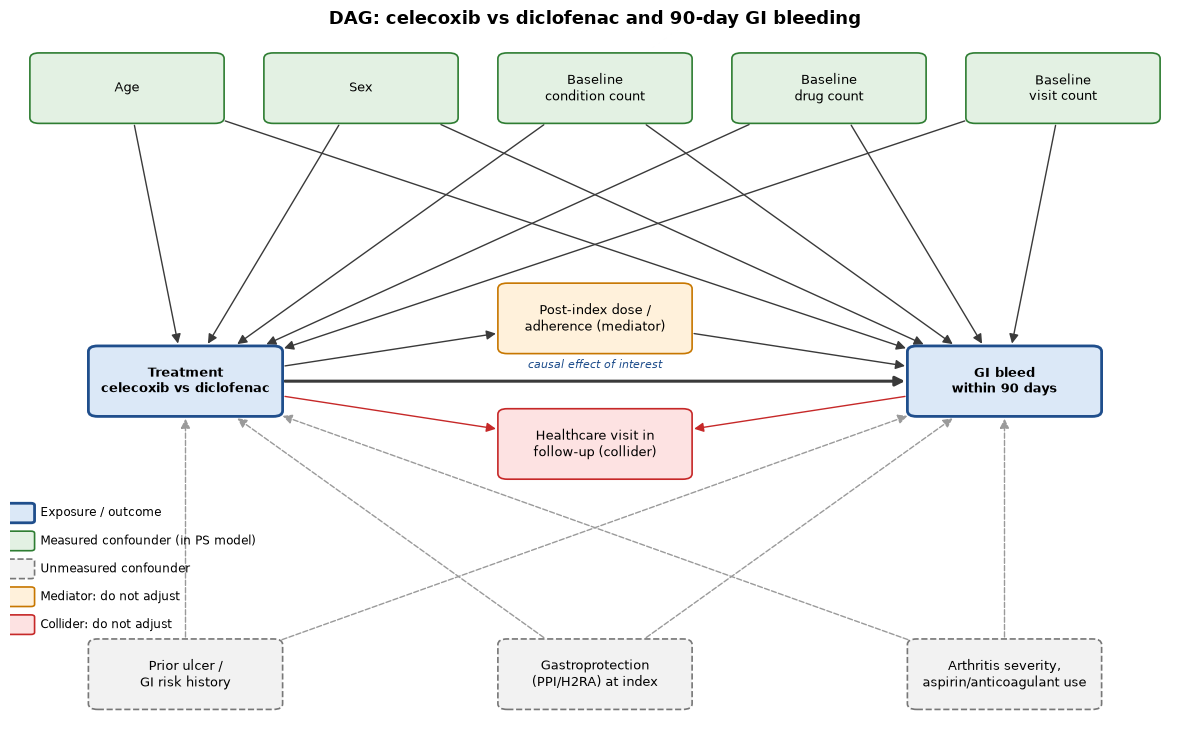

In [25]:
# Task 2: DAG — treatment, outcome, measured & unmeasured confounders, mediator (do not adjust), collider (do not adjust)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

nodes = {
    "T":      (0.15, 0.50, "Treatment\ncelecoxib vs diclofenac", "exposure"),
    "Y":      (0.85, 0.50, "GI bleed\nwithin 90 days", "outcome"),
    "age":    (0.10, 0.92, "Age", "measured"),
    "sex":    (0.30, 0.92, "Sex", "measured"),
    "cond":   (0.50, 0.92, "Baseline\ncondition count", "measured"),
    "drug":   (0.70, 0.92, "Baseline\ndrug count", "measured"),
    "visit":  (0.90, 0.92, "Baseline\nvisit count", "measured"),
    "girisk": (0.15, 0.08, "Prior ulcer /\nGI risk history", "unmeasured"),
    "ppi":    (0.50, 0.08, "Gastroprotection\n(PPI/H2RA) at index", "unmeasured"),
    "sev":    (0.85, 0.08, "Arthritis severity,\naspirin/anticoagulant use", "unmeasured"),
    "med":    (0.50, 0.59, "Post-index dose /\nadherence (mediator)", "mediator"),
    "col":    (0.50, 0.41, "Healthcare visit in\nfollow-up (collider)", "collider"),
}
confounders = ["age", "sex", "cond", "drug", "visit", "girisk", "ppi", "sev"]
edges = [(c, t) for c in confounders for t in ["T", "Y"]]
edges += [("T", "Y"), ("T", "med"), ("med", "Y"), ("T", "col"), ("Y", "col")]

style = {
    "exposure":   dict(fc="#dbe8f7", ec="#1f4e8c", ls="-",  lw=2.0),
    "outcome":    dict(fc="#dbe8f7", ec="#1f4e8c", ls="-",  lw=2.0),
    "measured":   dict(fc="#e3f1e3", ec="#2e7d32", ls="-",  lw=1.2),
    "unmeasured": dict(fc="#f2f2f2", ec="#777777", ls="--", lw=1.2),
    "mediator":   dict(fc="#fff1db", ec="#c77700", ls="-",  lw=1.2),
    "collider":   dict(fc="#fde2e2", ec="#c62828", ls="-",  lw=1.2),
}

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
w, h = 0.15, 0.085
boxes = {}
for name, (x, y, label, kind) in nodes.items():
    s = style[kind]
    boxes[name] = FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.008",
                                 fc=s["fc"], ec=s["ec"], ls=s["ls"], lw=s["lw"], zorder=3)
    ax.add_patch(boxes[name])
    ax.text(x, y, label, ha="center", va="center", fontsize=9, zorder=4,
            fontweight="bold" if kind in ("exposure", "outcome") else "normal")

for a, b in edges:
    unmeasured = nodes[a][3] == "unmeasured"
    color = "#9a9a9a" if unmeasured else ("#c62828" if b == "col" else "#3a3a3a")
    ax.annotate("", xy=nodes[b][:2], xytext=nodes[a][:2],
                arrowprops=dict(arrowstyle="-|>", mutation_scale=14, color=color,
                                lw=2.2 if (a, b) == ("T", "Y") else 1.0, ls="--" if unmeasured else "-",
                                patchA=boxes[a], patchB=boxes[b], shrinkA=1, shrinkB=1), zorder=2)
ax.text(0.5, 0.515, "causal effect of interest", ha="center", va="bottom", fontsize=8, style="italic", color="#1f4e8c")

legend = [("Exposure / outcome", "exposure"), ("Measured confounder (in PS model)", "measured"),
          ("Unmeasured confounder", "unmeasured"), ("Mediator: do not adjust", "mediator"),
          ("Collider: do not adjust", "collider")]
for i, (txt, kind) in enumerate(legend):
    s = style[kind]
    y0 = 0.30 - i * 0.04
    ax.add_patch(FancyBboxPatch((0.0, y0), 0.018, 0.022, boxstyle="round,pad=0.003",
                                fc=s["fc"], ec=s["ec"], ls=s["ls"], lw=s["lw"]))
    ax.text(0.026, y0 + 0.011, txt, va="center", fontsize=8.5)
ax.set_title("DAG: celecoxib vs diclofenac and 90-day GI bleeding", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

#### Target trial, estimand and assumptions

**Target trial question.** Among adult new users of celecoxib or diclofenac with no use of either drug and no GI bleed in the prior year, does starting celecoxib instead of diclofenac change the risk of a recorded GI bleed within 90 days?

| Component | Hypothetical target trial | Emulation in Eunomia GiBleed (OMOP) |
|---|---|---|
| Eligibility | Adults starting an NSAID, no use of either study drug and no GI bleed in the prior 365 days | First celecoxib or diclofenac exposure = index. ≥365 days of observation before index and ≥90 days after. No GI bleed (192671) in index −365 to −1 (none was recorded before index at any time). Same-day dual starts excluded (n = 0); no patient was exposed to both drugs |
| Treatment strategies | (1) Start celecoxib; (2) start diclofenac. Both arms continue usual care afterward | Treatment = 1 for celecoxib and 0 for diclofenac, assigned from the index drug |
| Assignment | Randomized | Assumed random conditional on baseline covariates L = age, sex, baseline condition, drug and visit counts (index −365 to −1), via a propensity score and stabilized IPTW |
| Time zero | Randomization = treatment start | Index date. Eligibility, assignment and start of follow-up all occur here, which avoids immortal time |
| Outcome | First GI bleed | First GI hemorrhage record (SNOMED 192671) from index +1 through index +90. Events on the index day are excluded |
| Follow-up | 90 days | Index +1 through index +90. Complete follow-up is required, so there is no censoring before day 90 |
| Causal contrast | Intention-to-treat | Observational analogue of intention-to-treat, based on the initial treatment regardless of switching, dose or adherence (no crossover observed) |
| Estimand | 90-day risk ratio (primary) and risk difference | Average treatment effect (ATE) in the eligible cohort |
| Analysis | Compare risks between arms | Stabilized-IPTW-weighted risks: RR from a weighted Poisson GLM, RD from a weighted linear GLM, robust SEs; crude estimates reported for comparison |

**Treatment strategies.** Strategy 1 is to initiate celecoxib at index; strategy 0 is to initiate diclofenac at index. Patients are analysed in the arm they started in for the full 90 days (intention-to-treat analogue), so later switching, discontinuation or dose changes do not change their group.

**Estimand.** The 90-day risk ratio of a documented GI bleed, celecoxib versus diclofenac, is the primary estimand; the 90-day risk difference is the secondary. Both target the average treatment effect (ATE) in the eligible population—that is, the difference between the effect if everyone received celecoxib and the effect if everyone started diclofenac—because stable IPTW reweights both arms to the covariate distribution of the entire cohort.

**Assumptions** *(evidence from Steps 5–9 below)*

| Assumption | Meaning | Assessment in this study |
|---|---|---|
| Conditional exchangeability | Given L, treatment choice is unrelated to the potential outcomes (no unmeasured confounding) | **Questionable.** Measured covariates are balanced after weighting (all \|SMD\| < 0.01), but gastroprotective co-medication and prior ulcer/GI-risk history are unmeasured and plausibly affect both drug choice and bleeding (see DAG). E-value = 1.88 (1.29 for the CI bound) |
| Positivity | Every covariate pattern has a non-zero chance of receiving either drug | **Supported.** PS overlap is good (celecoxib 0.31–0.90, diclofenac 0.53–0.89); only 5 patients fall outside common support; maximum stabilized weight 2.82 |
| Consistency | Each patient's observed outcome equals their potential outcome under the treatment received; the treatments are well defined | **Partly met.** Dose, formulation and duration are not recorded, so "celecoxib" and "diclofenac" may cover different regimens |
| No selection bias | The analysed cohort is representative of eligible initiators | **Possible threat.** 89 patients (3.3%) were excluded for less than 90 days of follow-up; if early loss of follow-up relates to treatment or prognosis, estimates may be biased |
| No outcome misclassification | The outcome is measured accurately and equally in both arms | **Possible threat.** A recorded diagnosis is not an adjudicated bleed; differential recording by arm is unlikely but cannot be ruled out |
| Correct PS model specification | The PS model captures how measured covariates relate to treatment | **Reasonable.** Main-effects logistic model achieved balance, and sensitivity analyses with alternative specifications gave the same RR (1.28–1.31) |

**Covariate selection.** None of the five covariates can be impacted by therapy because they are all measured in the 365 days before to index. Age and sex as general risk factors, as well as condition, medication, and visit counts as proxy for comorbidity and healthcare use, all plausibly affect both prescribing and bleeding risk. Even though only four patients have a non-zero value, the visit count is maintained as per policy. Post-index factors are purposefully left out: healthcare visits during follow-up are **colliders** (produced by both treatment and bleeding, so changing would create bias), and dose and adherence during follow-up are **mediators** (adjusting would block part of the impact).

**Conclusion on assumptions.** Positivity and balance on measured covariates are well supported, but exchangeability is the weak point, so the IPTW estimate should be read as an adjusted association rather than a proven causal effect.

## Task 3 — Propensity scores, IPTW and diagnostics

#### Step 5: Baseline table and SMDs

In [26]:
# Step 5: treatment-stratified baseline table with absolute standardized mean differences
import numpy as np

ads["male"] = (ads["sex"] == "M").astype(int)
covariates = ["age", "male", "baseline_condition_count", "baseline_drug_count", "baseline_visit_count"]

def smd(x, t, w=None):
    """Standardized mean difference (treated − control) / pooled SD; optional weights for IPTW."""
    x, t = np.asarray(x, float), np.asarray(t)
    w = np.ones(len(x)) if w is None else np.asarray(w, float)
    m1, m0 = np.average(x[t == 1], weights=w[t == 1]), np.average(x[t == 0], weights=w[t == 0])
    v1 = np.average((x[t == 1] - m1) ** 2, weights=w[t == 1])
    v0 = np.average((x[t == 0] - m0) ** 2, weights=w[t == 0])
    return (m1 - m0) / np.sqrt((v1 + v0) / 2)

rows = []
for cov in covariates:
    g = ads.groupby("treatment")[cov]
    if cov == "male":   # binary: n (%)
        fmt = lambda arm: f"{int(g.sum()[arm])} ({100 * g.mean()[arm]:.1f}%)"
    else:               # continuous / count: mean (SD)
        fmt = lambda arm: f"{g.mean()[arm]:.2f} ({g.std()[arm]:.2f})"
    rows.append((cov, fmt(1), fmt(0), abs(smd(ads[cov], ads["treatment"]))))

baseline_table = pd.DataFrame(rows, columns=["covariate", "celecoxib (n=1781)", "diclofenac (n=824)", "abs_smd_unweighted"])
baseline_table["imbalanced (>0.10)"] = baseline_table["abs_smd_unweighted"] > 0.10
baseline_table.round(3)

,covariate,celecoxib (n=1781),diclofenac (n=824),abs_smd_unweighted,imbalanced (>0.10)
0,age,38.17 (3.29),38.10 (3.25),0.022,False
1,male,885 (49.7%),391 (47.5%),0.045,False
2,baseline_condition_count,0.63 (0.83),0.45 (0.70),0.233,True
3,baseline_drug_count,0.32 (0.72),0.35 (0.71),0.044,False
4,baseline_visit_count,0.00 (0.04),0.00 (0.03),0.012,False


**Result:** Balanced on age, sex, drug and visit counts (|SMD| < 0.05); celecoxib users had more baseline conditions (SMD 0.23 > 0.10).
**Interpretation:** Consistent with confounding by indication; this imbalance is what the propensity score must correct (Austin 2009).

#### Step 6: Propensity score model

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,0.083,0.505,0.165,0.869,-0.906,1.073
age,0.013,0.013,1.022,0.307,-0.012,0.039
male,0.086,0.085,1.007,0.314,-0.081,0.252
baseline_condition_count,0.357,0.061,5.811,0.000,0.236,0.477
baseline_drug_count,-0.178,0.062,-2.845,0.004,-0.300,-0.055
baseline_visit_count,0.149,1.164,0.128,0.898,-2.133,2.431


,count,mean,std,min,25%,50%,75%,max
treatment,,,,,,,,
0,824.0,0.674,0.049,0.526,0.645,0.660,0.702,0.888
1,1781.0,0.688,0.058,0.308,0.649,0.667,0.728,0.895


c-statistic (AUC): 0.57


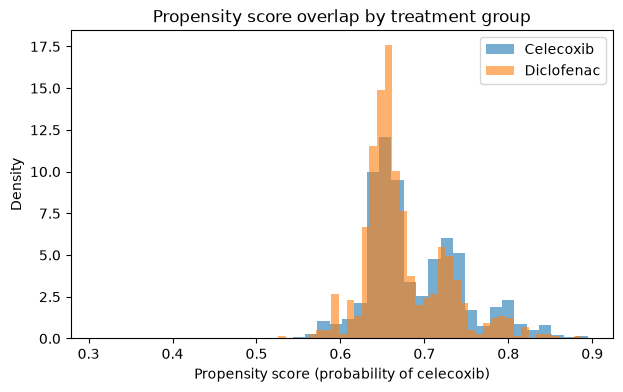

In [27]:
# Step 6: propensity score = P(celecoxib | baseline covariates), logistic regression with main effects
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

ps_formula = "treatment ~ age + male + baseline_condition_count + baseline_drug_count + baseline_visit_count"
ps_model = smf.logit(ps_formula, data=ads).fit(disp=0)
display(ps_model.summary2().tables[1].round(3))

ads["ps"] = ps_model.predict(ads)
display(ads.groupby("treatment")["ps"].describe().round(3))
print("c-statistic (AUC):", round(roc_auc_score(ads["treatment"], ads["ps"]), 3))

# overlap plot: PS distribution by arm
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ads.loc[ads["treatment"] == 1, "ps"], bins=40, alpha=0.6, density=True, label="Celecoxib")
ax.hist(ads.loc[ads["treatment"] == 0, "ps"], bins=40, alpha=0.6, density=True, label="Diclofenac")
ax.set_xlabel("Propensity score (probability of celecoxib)")
ax.set_ylabel("Density")
ax.set_title("Propensity score overlap by treatment group")
ax.legend()
plt.show()

**Result:** Baseline condition count is the main predictor of celecoxib (OR ≈ 1.43 per record); AUC = 0.57. PS ranges largely overlap (only 5 celecoxib patients outside the diclofenac range).
**Interpretation:** Good overlap supports positivity for weighting; low AUC reflects measured covariates only, not absence of confounding (Austin 2011).

#### Step 7: Stabilized IPTW and diagnostics

,count,mean,std,min,25%,50%,75%,max
treatment,,,,,,,,
0,824.0,0.999,0.203,0.667,0.890,0.930,1.060,2.818
1,1781.0,1.000,0.085,0.764,0.939,1.025,1.054,2.220


mean stabilized weight (should be ~1): 1.0


,patient_id,treatment,ps,sw
34,70,0,0.888,2.818
644,1309,1,0.308,2.220
2183,4450,0,0.857,2.215
732,1491,0,0.850,2.113
823,1662,0,0.847,2.065


Effective sample size: {0: 791.5, 1: 1768.1} | actual: {1: 1781, 0: 824}


,covariate,abs_smd_unweighted,abs_smd_weighted
0,age,0.022,0.003
1,male,0.045,0.001
2,baseline_condition_count,0.233,0.002
3,baseline_drug_count,0.044,0.009
4,baseline_visit_count,0.012,0.004


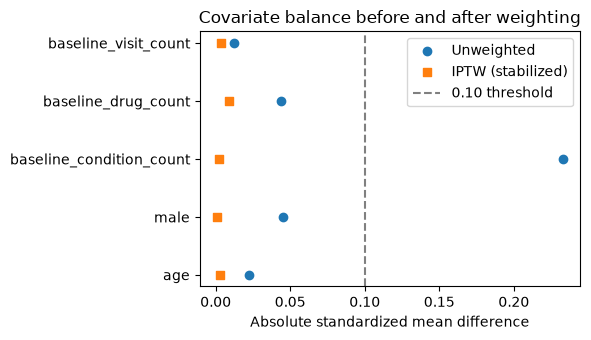

In [28]:
# Step 7: stabilized IPTW — celecoxib: P(T=1)/PS ; diclofenac: P(T=0)/(1−PS)
p_treat = ads["treatment"].mean()
ads["sw"] = np.where(ads["treatment"] == 1, p_treat / ads["ps"], (1 - p_treat) / (1 - ads["ps"]))

# weight diagnostics: distribution, extremes, effective sample size (ESS)
display(ads.groupby("treatment")["sw"].describe().round(3))
print("mean stabilized weight (should be ~1):", round(ads["sw"].mean(), 3))
display(ads.nlargest(5, "sw")[["patient_id", "treatment", "ps", "sw"]].round(3))

ess = ads.groupby("treatment")["sw"].apply(lambda w: w.sum() ** 2 / (w ** 2).sum())
print("Effective sample size:", ess.round(1).to_dict(), "| actual:", ads["treatment"].value_counts().to_dict())

# balance after weighting: reuse smd() from Step 5 with weights
balance = pd.DataFrame({
    "covariate": covariates,
    "abs_smd_unweighted": [abs(smd(ads[c], ads["treatment"])) for c in covariates],
    "abs_smd_weighted": [abs(smd(ads[c], ads["treatment"], ads["sw"])) for c in covariates],
})
display(balance.round(3))

# Love plot
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(balance["abs_smd_unweighted"], balance["covariate"], label="Unweighted", marker="o")
ax.scatter(balance["abs_smd_weighted"], balance["covariate"], label="IPTW (stabilized)", marker="s")
ax.axvline(0.10, linestyle="--", color="grey", label="0.10 threshold")
ax.set_xlabel("Absolute standardized mean difference")
ax.set_title("Covariate balance before and after weighting")
ax.legend()
plt.tight_layout()
plt.show()

**Result:** Stabilized weights average 1.0 (max 2.82); effective sample size 1,768 of 1,781 and 792 of 824. All weighted |SMD| < 0.01 (condition count 0.233 → 0.002).
**Interpretation:** No extreme weights and excellent balance on measured covariates; unmeasured confounders (e.g. gastroprotective co-medication, Shin 2018) remain unaddressed.

#### Step 8: Crude vs IPTW-adjusted risk ratio and risk difference

In [29]:
# Step 8: crude and IPTW-adjusted 90-day risk ratio (RR) and risk difference (RD) with 95% CIs
import statsmodels.api as sm

y, t, w = ads["gi_bleed_90d"], ads["treatment"], ads["sw"]
X = sm.add_constant(t)

def fit_effects(weights=None):
    """RR from Poisson (log link) and RD from linear model, both with robust SEs."""
    kw = {} if weights is None else {"var_weights": weights}
    rr_fit = sm.GLM(y, X, family=sm.families.Poisson(), **kw).fit(cov_type="HC0")
    rd_fit = sm.GLM(y, X, family=sm.families.Gaussian(), **kw).fit(cov_type="HC0")
    rr, rr_ci = np.exp(rr_fit.params["treatment"]), np.exp(rr_fit.conf_int().loc["treatment"]).values
    rd, rd_ci = rd_fit.params["treatment"], rd_fit.conf_int().loc["treatment"].values
    return rr, rr_ci, rd, rd_ci

results = []
for label, weights in [("Crude", None), ("IPTW-adjusted (stabilized)", w)]:
    rr, rr_ci, rd, rd_ci = fit_effects(weights)
    wts = np.ones(len(y)) if weights is None else weights
    risk1 = np.average(y[t == 1], weights=wts[t == 1])
    risk0 = np.average(y[t == 0], weights=wts[t == 0])
    results.append((label, risk1, risk0, rr, *rr_ci, rd, *rd_ci))

effects = pd.DataFrame(results, columns=["analysis", "risk_celecoxib", "risk_diclofenac",
                                         "RR", "RR_low", "RR_high", "RD", "RD_low", "RD_high"])
effects.round(4)

,analysis,risk_celecoxib,risk_diclofenac,RR,RR_low,RR_high,RD,RD_low,RD_high
0,Crude,0.1926,0.1468,1.3115,1.0845,1.5861,0.0457,0.0154,0.0761
1,IPTW-adjusted (stabilized),0.1878,0.1468,1.2798,1.0547,1.5530,0.0411,0.0105,0.0716


**Result:** Crude RR 1.31 (95% CI 1.08–1.59), RD 4.6% (1.5–7.6%); IPTW RR 1.28 (1.05–1.55), RD 4.1% (1.1–7.2%).
**Interpretation:** Adjustment changed the estimate only slightly, so measured confounding explains little of the crude association. Robust SEs ignore PS estimation and are typically conservative for IPTW.

## Task 4 — Confounding distortion, robustness and innovation

#### Step 9: Confounding distortion and sensitivity analyses

In [30]:
#confounding distortion D = log(RR_crude) − log(RR_adjusted)
rr_crude = effects.loc[effects["analysis"] == "Crude", "RR"].item()
rr_adj = effects.loc[effects["analysis"].str.startswith("IPTW"), "RR"].item()
D = np.log(rr_crude) - np.log(rr_adj)
print(f"RR crude = {rr_crude:.3f} | RR adjusted = {rr_adj:.3f} | D = {D:.4f} (crude is {100 * (np.exp(D) - 1):.1f}% higher)")

RR crude = 1.312 | RR adjusted = 1.280 | D = 0.0244 (crude is 2.5% higher)


**Result:** D = 0.024 (crude RR 1.31 vs adjusted 1.28), so the crude estimate was about 2.5% higher.
**Interpretation:** Positive but small: measured confounding slightly exaggerated celecoxib's risk. D is a change-in-estimate diagnostic, not the true total bias, because it ignores unmeasured confounders, weak covariates and PS-model misspecification.

In [31]:
#sensitivity analyses — re-estimate IPTW RR under alternative choices
def iptw_rr(df, formula=ps_formula, trunc=None):
    """Refit PS, build stabilized weights (optionally truncated at percentiles), return RR with robust 95% CI."""
    df = df.copy()
    ps = smf.logit(formula, data=df).fit(disp=0).predict(df)
    pt = df["treatment"].mean()
    sw = np.where(df["treatment"] == 1, pt / ps, (1 - pt) / (1 - ps))
    if trunc:
        sw = np.clip(sw, *np.percentile(sw, trunc))
    fit = sm.GLM(df["gi_bleed_90d"], sm.add_constant(df["treatment"]),
                 family=sm.families.Poisson(), var_weights=sw).fit(cov_type="HC0")
    lo, hi = np.exp(fit.conf_int().loc["treatment"])
    return len(df), np.exp(fit.params["treatment"]), lo, hi, sw.max()

# overlap restriction: keep patients inside the PS range shared by both arms
cs_lo = max(ads.groupby("treatment")["ps"].min())
cs_hi = min(ads.groupby("treatment")["ps"].max())
common_support = ads[ads["ps"].between(cs_lo, cs_hi)]

sens = pd.DataFrame([
    ("Primary: stabilized IPTW, all covariates", *iptw_rr(ads)),
    ("Weights truncated at 1st/99th percentile", *iptw_rr(ads, trunc=[1, 99])),
    ("Weights truncated at 5th/95th percentile", *iptw_rr(ads, trunc=[5, 95])),
    ("Overlap restriction (common support)", *iptw_rr(common_support)),
    ("Alternative PS: drop visit count", *iptw_rr(ads, "treatment ~ age + male + baseline_condition_count + baseline_drug_count")),
    ("Alternative PS: age + sex only", *iptw_rr(ads, "treatment ~ age + male")),
], columns=["analysis", "n", "RR", "RR_low", "RR_high", "max_weight"])
sens.round(3)

,analysis,n,RR,RR_low,RR_high,max_weight
0,"Primary: stabilized IPTW, all covariates",2605,1.280,1.055,1.553,2.818
1,Weights truncated at 1st/99th percentile,2605,1.285,1.060,1.558,1.552
2,Weights truncated at 5th/95th percentile,2605,1.283,1.059,1.553,1.185
3,Overlap restriction (common support),2600,1.280,1.055,1.553,2.675
4,Alternative PS: drop visit count,2605,1.280,1.055,1.553,2.822
5,Alternative PS: age + sex only,2605,1.310,1.083,1.585,1.073


**Result:** RR stays between 1.28 and 1.31 across weight truncation, overlap restriction and alternative PS models; all CIs exclude 1.
**Interpretation:** The estimate is robust to weighting and model choices. The age + sex model reproduces the crude RR, showing baseline condition count drives the adjustment.

In [32]:
def e_value(rr):
    rr = max(rr, 1 / rr)
    return rr + np.sqrt(rr * (rr - 1))

rr_low = effects.loc[effects["analysis"].str.startswith("IPTW"), "RR_low"].item()
print(f"E-value (point estimate): {e_value(rr_adj):.2f} | E-value (CI lower bound): {e_value(rr_low):.2f}")

E-value (point estimate): 1.88 | E-value (CI lower bound): 1.29


**Result:** E-value 1.88 (point estimate) and 1.29 (CI lower bound).
**Interpretation:** An unmeasured confounder associated with both treatment and GI bleeding by RR ≈ 1.9 could explain away the effect, and RR ≈ 1.3 could make it non-significant. Gastroprotective co-medication (Shin 2018) could plausibly be that strong (VanderWeele & Ding 2017).

## Task 5 — Scientific interpretation

**Cohort feasibility.** There were 2,605 new users: 1,781 on celecoxib and 824 on diclofenac. The only criterion that excluded anyone was the 90-day follow-up requirement (89 patients). Both arms had sufficient events (343 and 121 GI bleeds), so sparsity was not a concern. The data are synthetic, with a trimmed vocabulary and exposures coded at ingredient level.

**Crude vs adjusted findings.** Crude 90-day GI bleed risks were 19.3% for celecoxib and 14.7% for diclofenac: RR 1.31 (95% CI 1.08–1.59), RD 4.6%. After IPTW, the RR was 1.28 (1.05–1.55) and the RD 4.1% (about 4 extra bleeds per 100). Adjustment changed the estimate only slightly (D = 0.024). Sensitivity analyses using weight truncation, overlap restriction and alternative PS specifications gave RRs of 1.28–1.31.

**Balance and positivity.** Before weighting, only baseline condition count was imbalanced (SMD 0.23, higher with celecoxib), consistent with channeling of sicker patients to celecoxib. After weighting, all SMDs were below 0.01. Overlap was good (PS AUC 0.57), the maximum weight was 2.82 and the effective sample size was 96–99%, so positivity was not a concern.

**Key limitations.**
- *Unmeasured confounding.* PPI use and ulcer history are not in the model, and aspirin or anticoagulant use was not adjusted for, though these drive COX-2 selective prescribing. The E-value is 1.88, but an unmeasured confounder associated with treatment and outcome at about RR 1.3 could move the CI to include 1.
- *Weak covariates.* The five covariates are crude record counts rather than specific conditions, and visit count was almost always zero, so balance on them says little about true GI risk.
- *Outcome definition.* The outcome is a recorded diagnosis code, not a validated bleed.
- *Selection bias.* Requiring complete 90-day follow-up may introduce selection bias.

**Causal interpretation.** A causal claim is not defensible. Checks on measured data all pass: balance, overlap, stable weights and robust sensitivity analyses. These checks cannot test exchangeability, and the most important GI-risk confounders are unmeasured. The result is best stated as an adjusted association consistent with higher GI-bleed risk for celecoxib, not a demonstrated causal effect, and, being synthetic, not real-world safety evidence.

**Practical improvement.** Replace the record counts with specific baseline covariates that this dataset already contains: prior peptic ulcer (802 records), aspirin, clopidogrel, warfarin, heparin and corticosteroid use. Including them would directly test whether the RR of about 1.28 survives adjustment for channeling. PPIs and H2 blockers are absent from these data.